<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="300" alt="Skills Network Logo">
    </a>
</p>


# **Hands-on practice lab: Model Development**

Estimated time needed: **45** minutes

In this lab, you will use the skills acquired in throughout the module, and use linear regression principles to create a model that predicts the Price of the laptop, based on one or more attributes of the dataset.


# Objectives

After completing this lab you will be able to:

 - Use Linear Regression in one variable to fit the parameters to a model
 - Use Linear Regression in multiple variables to fit the parameters to a model
 - Use Polynomial Regression in single variable tofit the parameters to a model
 - Create a pipeline for performing linear regression using multiple features in polynomial scaling
 - Evaluate the performance of different forms of regression on basis of MSE and R^2 parameters


# Setup


For this lab, we will be using the following libraries:

*   [`pandas`](https://pandas.pydata.org/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMML0187ENSkillsNetwork31430127-2021-01-01) for managing the data.
*   [`numpy`](https://numpy.org/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMML0187ENSkillsNetwork31430127-2021-01-01) for mathematical operations.
*   [`sklearn`](https://scikit-learn.org/stable/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMML0187ENSkillsNetwork31430127-2021-01-01) for machine learning and machine-learning-pipeline related functions.
*   [`seaborn`](https://seaborn.pydata.org/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMML0187ENSkillsNetwork31430127-2021-01-01) for visualizing the data.
*   [`matplotlib`](https://matplotlib.org/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMML0187ENSkillsNetwork31430127-2021-01-01) for additional plotting tools.


Libraries are installed in the local Python environment.

The browser-only installer is unnecessary here.

### Importing Required Libraries

_We recommend you import all required libraries in one place (here):_


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, r2_score
%matplotlib inline

### Use the supplied local dataset
This task uses the provided `laptops.csv`, not the online replacement. CPU_frequency is in GHz. The selected seven predictors are complete; the missing screen sizes and weights are not used by these models.

The browser-only download helper is unnecessary for the included local CSV.

We put the file path along with a quotation mark so that pandas will read the file into a dataframe from that address. The file path can be either an URL or your local file address.


The original online input was a processed version. We retain the user-supplied local version and its units; no repeated scaling or unit conversion is applied before the requested tasks.

Select the local file:

In [2]:
file_name = "laptops.csv"

Load the dataset into a pandas dataframe


In [3]:
df = pd.read_csv(file_name, index_col=0)
model_features = ["CPU_frequency", "RAM_GB", "Storage_GB_SSD", "CPU_core", "OS", "GPU", "Category"]
assert not df[model_features + ["Price"]].isna().any().any()
print("Input:", df.shape, "— all requested model fields complete")

Input: (238, 12) — all requested model fields complete


The first column is a saved row index, not a predictor. We keep all 238 observations and 12 actual fields. All metrics below are training-set metrics, not held-out performance.

Local reading is performed once above.

In [4]:
# show the first 5 rows using dataframe.head() method
print("The first 5 rows of the dataframe") 
df.head(5)

The first 5 rows of the dataframe


,Manufacturer,Category,Screen,GPU,OS,CPU_core,Screen_Size_cm,CPU_frequency,RAM_GB,Storage_GB_SSD,Weight_kg,Price
0,Acer,4,IPS Panel,2,1,5,35.560,1.6,8,256,1.60,978
1,Dell,3,Full HD,1,1,3,39.624,2.0,4,256,2.20,634
2,Dell,3,Full HD,1,1,7,39.624,2.7,8,256,2.20,946
3,Dell,4,IPS Panel,2,1,5,33.782,1.6,8,128,1.22,1244
4,HP,4,Full HD,2,1,7,39.624,1.8,8,256,1.91,837


# Task 1 : Single Linear Regression

You have learnt that "CPU_frequency" is the parameter with the lowest p-value among the different features of the dataset. Create a single feature Linear Regression model that fits the pair of "CPU_frequency" and "Price" to find the model for prediction.


Correction: CPU_frequency did not have the lowest p-value in the Module 03 results; RAM_GB had a lower p-value. We use CPU_frequency here because it is explicitly requested.

In [5]:
lm = LinearRegression()
X = df[["CPU_frequency"]]
Y = df["Price"]
lm.fit(X, Y)
Yhat = lm.predict(X)
print(f"Price = {lm.intercept_:.4f} + {lm.coef_[0]:.4f} * CPU_frequency (GHz)")
Yhat[:5]

Price = 253.6612 + 512.1357 * CPU_frequency (GHz)


array([1073.07834392, 1277.93263722, 1636.42765051, 1073.07834392,
       1175.50549057])

<details>
    <summary>Click here for Solution</summary>

```python
lm = LinearRegression()

X = df[['CPU_frequency']]
Y = df['Price']

lm.fit(X,Y)

Yhat=lm.predict(X)
```

</details>


Generate the Distribution plot for the predicted values and that of the actual values. How well did the model perform?


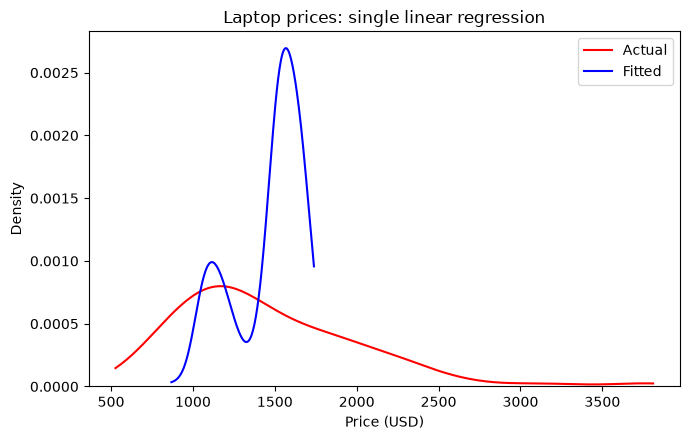

The fitted distribution is narrower than the observed prices; CPU frequency alone misses substantial variability.


In [6]:
plt.figure(figsize=(7, 4.5))
sns.kdeplot(x=df["Price"], color="red", label="Actual", cut=0)
sns.kdeplot(x=Yhat, color="blue", label="Fitted", cut=0)
plt.title("Laptop prices: single linear regression")
plt.xlabel("Price (USD)")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.show()
print("The fitted distribution is narrower than the observed prices; CPU frequency alone misses substantial variability.")

<details>
    <summary>Click here for Solution</summary>

```python
ax1 = sns.distplot(df['Price'], hist=False, color="r", label="Actual Value")

# Create a distribution plot for predicted values
sns.distplot(Yhat, hist=False, color="b", label="Fitted Values" , ax=ax1)

plt.title('Actual vs Fitted Values for Price')
plt.xlabel('Price')
plt.ylabel('Proportion of laptops')
plt.legend(['Actual Value', 'Predicted Value'])
plt.show()
```

</details>


Evaluate the Mean Squared Error and R^2 score values for the model. 


In [7]:
mse_slr = mean_squared_error(Y, Yhat)
r2_score_slr = r2_score(Y, Yhat)
print("Training R2:", r2_score_slr)
print("Training MSE:", mse_slr)

Training R2: 0.1344436321024326
Training MSE: 284583.4405868629


<details>
    <summary>Click here for Solution</summary>

```python
mse_slr = mean_squared_error(df['Price'], Yhat)
r2_score_slr = lm.score(X, Y)
print('The R-square for Linear Regression is: ', r2_score_slr)
print('The mean square error of price and predicted value is: ', mse_slr)
```

</details>


# Task 2 - Multiple Linear Regression
The parameters which have a low enough p-value so as to indicate strong relationship with the 'Price' value are 'CPU_frequency', 'RAM_GB', 'Storage_GB_SSD', 'CPU_core', 'OS', 'GPU' and 'Category'. Use all these variables to create a Multiple Linear Regression system. 


A small p-value does not by itself imply a strong effect. GPU and Category are nominal codes; they are used numerically as this exercise requests, but the results depend on that representation.

In [8]:
Z = df[model_features]
lm1 = LinearRegression()
lm1.fit(Z, Y)
Y_hat = lm1.predict(Z)
Y_hat[:5]

array([1345.51622771,  710.44905496, 1552.37242687, 1295.00681012,
       1543.13847022])

<details>
    <summary>Click here for Solution</summary>

```python
lm1 = LinearRegression()
Z = df[['CPU_frequency','RAM_GB','Storage_GB_SSD','CPU_core','OS','GPU','Category']]
lm1.fit(Z,Y)
Y_hat = lm1.predict(Z)
```

</details>


Plot the Distribution graph of the predicted values as well as the Actual values


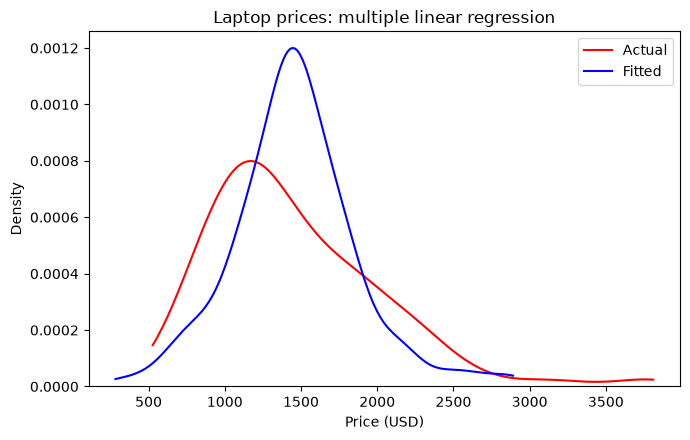

In [9]:
plt.figure(figsize=(7, 4.5))
sns.kdeplot(x=df["Price"], color="red", label="Actual", cut=0)
sns.kdeplot(x=Y_hat, color="blue", label="Fitted", cut=0)
plt.title("Laptop prices: multiple linear regression")
plt.xlabel("Price (USD)")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.show()

<details>
    <summary>Click here for Solution</summary>

```python
ax1 = sns.distplot(df['Price'], hist=False, color="r", label="Actual Value")
sns.distplot(Y_hat, hist=False, color="b", label="Fitted Values" , ax=ax1)

plt.title('Actual vs Fitted Values for Price')
plt.xlabel('Price')
plt.ylabel('Proportion of laptops')

```

</details>


Find the R^2 score and the MSE value for this fit. Is this better or worst than the performance of Single Linear Regression?


In [10]:
mse_mlr = mean_squared_error(Y, Y_hat)
r2_mlr = r2_score(Y, Y_hat)
print("Training R2:", r2_mlr)
print("Training MSE:", mse_mlr)
print("Better training fit than SLR:", mse_mlr < mse_slr and r2_mlr > r2_score_slr)

Training R2: 0.5082509055187374
Training MSE: 161680.5726389311
Better training fit than SLR: True


The comparison above uses R² and MSE. KDE overlap alone is insufficient to measure prediction error; improved training fit does not establish better performance on new laptops.

# Task 3 - Polynomial Regression
Use the variable "CPU_frequency" to create Polynomial features. Try this for 3 different values of polynomial degrees. Remember that polynomial fits are done using `numpy.polyfit`. 


In [11]:
x_cpu = X.to_numpy().ravel()
f1 = np.polyfit(x_cpu, Y, 1)
p1 = np.poly1d(f1)
f3 = np.polyfit(x_cpu, Y, 3)
p3 = np.poly1d(f3)
f5 = np.polyfit(x_cpu, Y, 5)
p5 = np.poly1d(f5)

<details>
    <summary>Click here for Solution</summary>

```python
X = X.to_numpy().flatten()
f1 = np.polyfit(X, Y, 1)
p1 = np.poly1d(f1)

f3 = np.polyfit(X, Y, 3)
p3 = np.poly1d(f3)

f5 = np.polyfit(X, Y, 5)
p5 = np.poly1d(f5)
```

</details>


Plot the regression output against the actual data points to note how the data fits in each case. To plot the polynomial response over the actual data points, you have the function shown below.


In [12]:
def PlotPolly(model, independent_variable, dependent_variable, Name):
    grid = np.linspace(independent_variable.min(), independent_variable.max(), 300)
    plt.figure(figsize=(7, 4.5))
    plt.scatter(independent_variable, dependent_variable, s=18, alpha=0.6, label="Actual")
    plt.plot(grid, model(grid), color="red", label="Polynomial fit")
    plt.xlabel(Name)
    plt.ylabel("Price (USD)")
    plt.title(f"Polynomial fit: {Name}")
    plt.legend()
    plt.tight_layout()
    plt.show()

Call this function for the 3 models created and get the required graphs.


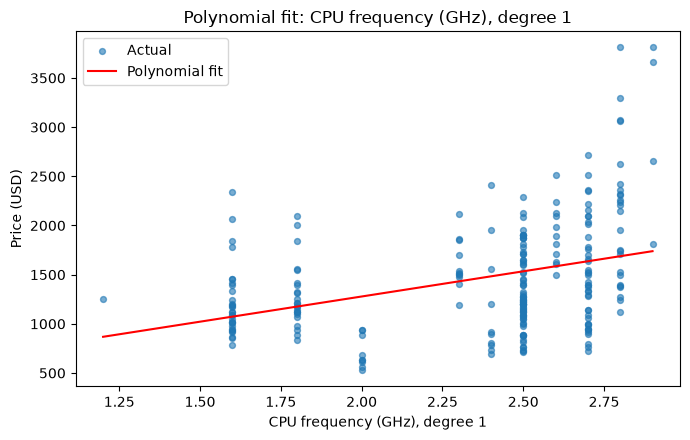

In [13]:
PlotPolly(p1, x_cpu, Y, "CPU frequency (GHz), degree 1")

<details>
    <summary>Click here for Solution</summary>
    
```python
PlotPolly(p1, X, Y, 'CPU_frequency')
```

</details>


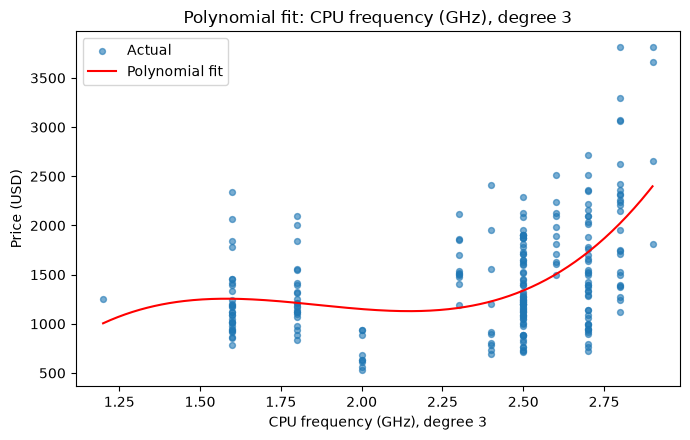

In [14]:
PlotPolly(p3, x_cpu, Y, "CPU frequency (GHz), degree 3")

<details>
    <summary>Click here for Solution</summary>
    
```python
PlotPolly(p3, X, Y, 'CPU_frequency')
```

</details>


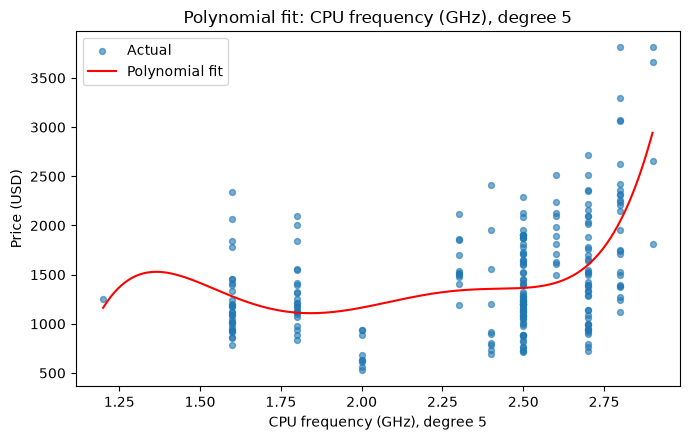

In [15]:
PlotPolly(p5, x_cpu, Y, "CPU frequency (GHz), degree 5")

<details>
    <summary>Click here for Solution</summary>
    
```python
PlotPolly(p5, X, Y, 'CPU_frequency')
```

</details>


Also, calculate the R^2 and MSE values for these fits. For polynomial functions, the function sklearn.metrics.r2_score will be used to calculate R^2 values.


In [16]:
for degree, model in [(1, p1), (3, p3), (5, p5)]:
    print(f"Degree {degree}: training R2={r2_score(Y, model(x_cpu)):.6f}; MSE={mean_squared_error(Y, model(x_cpu)):.6f}")

Degree 1: training R2=0.134444; MSE=284583.440587
Degree 3: training R2=0.266926; MSE=241024.863038
Degree 5: training R2=0.303082; MSE=229137.295481


<details>
    <summary>Click here for Solution</summary>
    
```python
r_squared_1 = r2_score(Y, p1(X))
print('The R-square value for 1st degree polynomial is: ', r_squared_1)
print('The MSE value for 1st degree polynomial is: ', mean_squared_error(Y,p1(X)))
r_squared_3 = r2_score(Y, p3(X))
print('The R-square value for 3rd degree polynomial is: ', r_squared_3)
print('The MSE value for 3rd degree polynomial is: ', mean_squared_error(Y,p3(X)))
r_squared_5 = r2_score(Y, p5(X))
print('The R-square value for 5th degree polynomial is: ', r_squared_5)
print('The MSE value for 5th degree polynomial is: ', mean_squared_error(Y,p5(X)))
```

</details>


# Task 4 - Pipeline
Create a pipeline that performs parameter scaling, Polynomial Feature generation and Linear regression. Use the set of multiple features as before to create this pipeline. 


In [17]:
Input = [("scale", StandardScaler()), ("polynomial", PolynomialFeatures(degree=2, include_bias=False)), ("model", LinearRegression())]
pipe = Pipeline(Input)
Z = Z.astype(float)
pipe.fit(Z, Y)
ypipe = pipe.predict(Z)
ypipe[:5]

array([1484.18227261,  778.36551848, 1267.81424349, 1009.69942066,
       1505.21474521])

<details>
    <summary>Click here for Solution</summary>
    
```python
Input=[('scale',StandardScaler()), ('polynomial', PolynomialFeatures(include_bias=False)), ('model',LinearRegression())]
pipe=Pipeline(Input)
Z = Z.astype(float)
pipe.fit(Z,Y)
ypipe=pipe.predict(Z)
```

</details>


Evaluate the MSE and R^2 values for the this predicted output.


In [18]:
print("Training MSE for polynomial pipeline:", mean_squared_error(Y, ypipe))
print("Training R2 for polynomial pipeline:", r2_score(Y, ypipe))

Training MSE for polynomial pipeline: 120595.86128028373
Training R2 for polynomial pipeline: 0.6332094535859658


<details>
    <summary>Click here for Solution</summary>
    
```python
print('MSE for multi-variable polynomial pipeline is: ', mean_squared_error(Y, ypipe))
print('R^2 for multi-variable polynomial pipeline is: ', r2_score(Y, ypipe))

```

</details>


You should now have seen that the values of R^2 increase as we go from Single Linear Regression to Multiple Linear Regression. Further, if we go for multiple linear regression extended with polynomial features, we get an even better R^2 value.


These improvements are in-sample. Adding polynomial terms increases flexibility and may overfit. Compare generalization with held-out data in Module 05; a higher training R² is not evidence of greater real-world accuracy.

In [19]:
predictions = {"SLR_CPU":Yhat, "MLR_seven_features":Y_hat, "Polynomial_degree1":p1(x_cpu), "Polynomial_degree3":p3(x_cpu), "Polynomial_degree5":p5(x_cpu), "Polynomial_pipeline_degree2":ypipe}
rows=[]
for name, prediction in predictions.items():
    assert len(prediction)==238 and np.isfinite(prediction).all()
    mse_value=mean_squared_error(Y,prediction)
    r2_value=r2_score(Y,prediction)
    assert np.isclose(r2_value,1-mse_value/np.var(Y))
    rows.append({"model":name,"training_R2":r2_value,"training_MSE_USD2":mse_value})
assert np.allclose(Yhat,p1(x_cpu))
assert mse_mlr <= mse_slr
metrics=pd.DataFrame(rows)
metrics.to_csv("Lab02_model_metrics.csv",index=False)
pd.DataFrame({"Actual":Y,**predictions}).to_csv("Lab02_predictions.csv",index=False)
print("All checks passed. All 238 rows retained; no missing-value imputation needed for selected features.")
metrics

All checks passed. All 238 rows retained; no missing-value imputation needed for selected features.


,model,training_R2,training_MSE_USD2
0,SLR_CPU,0.134444,284583.440587
1,MLR_seven_features,0.508251,161680.572639
2,Polynomial_degree1,0.134444,284583.440587
3,Polynomial_degree3,0.266926,241024.863038
4,Polynomial_degree5,0.303082,229137.295481
5,Polynomial_pipeline_degree2,0.633209,120595.861280


# Congratulations! You have completed the lab


## Authors


[Abhishek Gagneja](https://www.coursera.org/instructor/~129186572)

[Vicky Kuo](https://author.skills.network/instructors/vicky_kuo)


### Copyright ©IBM Corporation. All rights reserved.


<!--## Change Log


<!--|Date (YYYY-MM-DD)|Version|Changed By|Change Description|
|-|-|-|-|
|2023-09-16|0.1|Abhishek Gagneja|Initial Version Created|
|2023-09-19|0.2|Vicky Kuo|Reviewed and Revised|--!>
